# Análisis exploratorio de tickets y tiempo muerto

Se revisan los tickets de mantenimiento y los registros de paro de los dos archivos. La estructura sigue la *Guía para un análisis descriptivo*, de Omar Mendoza Montoya (09/09/2026): variables, calidad, distribuciones, relaciones y comportamiento temporal.

La población de interés son los tickets y paros de los equipos de la planta. Los archivos son un extracto de registros, sin un diseño de muestreo conocido. Los resultados describen este extracto y no permiten estimar por sí solos el comportamiento de toda la planta.

Para ejecutar: abrir este notebook desde la carpeta de los archivos, seleccionar el Python de `.venv` y ejecutar todas las celdas. Las dependencias están en `requirements.txt`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_rows", 80)
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4)

## 1. Datos y variables

Se usan las hojas `Data` y `2024`, que contienen los registros actuales. Las hojas de pivotes, catálogos y resúmenes no se añaden como observaciones. La hoja histórica `2020-2021` tiene otra estructura y queda fuera de este análisis. Los nombres de los archivos y hojas no indican el periodo real.

Una fila de tickets es un registro de solicitud. Una fila de paros es un intervalo de tiempo muerto; un ticket puede aparecer en varios intervalos.

In [2]:
tickets_raw = pd.read_excel("Clasificacion de Tickets 2021.xlsm", sheet_name="Data")
paros_raw = pd.read_excel("Resumen Downtime Current.xlsx", sheet_name="2024")
tickets_raw.columns = tickets_raw.columns.str.strip()
paros_raw.columns = paros_raw.columns.str.strip()

for nombre, df in [("Tickets", tickets_raw), ("Paros", paros_raw)]:
    print(nombre, df.shape)
    print("Periodo:", df["Opened"].min(), "a", df["Opened"].max())
    display(df.head(3))

Tickets (11150, 42)
Periodo: 2025-01-01 00:00:00 a 2026-08-24 22:36:05


,Number,State,Equipment Name,Assigned to,Updated,Opened,...,Eq,Val,Duplicado,Tickets found,Total repair time,Time of response
0,REQ-1761298,Completed,Robusta,NaN,2026-08-24 22:40:13,2026-08-24 22:36:05,...,IMM - Robusta,1.000,1.000,NaN,NaN,NaN
1,REQ-1761297,Completed,Robusta,NaN,2026-08-24 22:38:09,2026-08-24 22:34:44,...,IMM - Robusta,1.000,1.000,NaN,NaN,NaN
2,REQ-1761296,Completed,Aguascalientes,NaN,2026-08-26 02:23:49,2026-08-24 22:33:22,...,IMM - Aguascalientes,1.000,1.000,NaN,NaN,NaN


Paros (10167, 28)
Periodo: 2025-01-02 01:45:23.170000 a 2026-08-23 23:50:52.500000


,Equipo,Opened,Update,Reason,Ticket,Downtime,...,Corrective,Class2 29,Eq Type 26,Automotive? As on Aug-2024,Brand,Model
0,Preferida,2026-08-23 23:50:52.500,2026-08-24 00:14:31.837,MANTENIMIENTO - MANTTO. CORRECTIVO,REQ-1760551,0.394,...,Corrective,Robot Wrist problem,Robot,NO,SEPRO,S5-35 S3 AXIAL
1,LaBarranca,2026-08-23 23:25:43.213,2026-08-23 23:27:48.213,MANTENIMIENTO - MANTTO. CORRECTIVO,REQ-1760257,0.035,...,Corrective,Clamping/ejector movement problems,IMM,NO,KRAUSS MAFFEI,KM420-1900C2
2,Ruisenores,2026-08-23 23:21:46.997,2026-08-24 00:05:28.297,MANTENIMIENTO - MANTTO. CORRECTIVO,REQ-1760550,0.728,...,Corrective,Oil Alarm,IMM,NO,NISSEI,FV9000


El inventario incluye todas las columnas de las dos hojas. Las definiciones se apoyan en los encabezados y en sus valores. Los campos auxiliares sin definición confiable se conservan en el inventario, pero no se interpretan como medidas.

`Repair Time` se interpreta provisionalmente en horas; el archivo no trae un diccionario que confirme esa unidad. `Downtime` está en horas, lo que se comprueba con la diferencia entre `Update` y `Opened`. `Close date supervisor` contiene importes y `Eq2` contiene monedas: no se usan como fechas ni se suman importes de monedas distintas.

In [3]:
variables_tickets = """Number|Identificador|Código de ticket
State|Categórica nominal|Estado de la solicitud
Equipment Name|Identificador|Nombre del equipo
Assigned to|Sin datos|Responsable; columna vacía
Updated|Fecha / texto mixto|Actualización; también contiene turnos
Opened|Fecha|Apertura del ticket
Repair Time|Numérica continua|Tiempo de reparación; horas supuestas
 time 24|Categórica nominal|Estado operativo del registro, no duración
Description|Texto libre|Descripción de la solicitud
Requested for|Identificador|Solicitante
Functional area|Categórica nominal|Área funcional
Major Code|Categórica nominal|Clasificación principal
Minor code|Categórica nominal|Clasificación específica
Active|Categórica nominal|Tipo de servicio, no indicador lógico
Problem Type|Binaria|Condición Up/Down
Workgroup|Categórica nominal|Grupo de mantenimiento
Work Description (Close Details)|Texto libre|Trabajo realizado
Location|Identificador|Ubicación indicada
Equipment Location|Identificador|Ubicación del equipo
Equipment ID|Identificador|Código del equipo
Date created|Fecha|Creación del registro
Work end|Fecha|Fin de trabajo registrado
Close date supervisor|Numérica / texto mixto|Importe aparente; encabezado incorrecto
Eq2|Categórica nominal|Moneda del importe aparente
Fecha|Fecha agrupada|Año y mes de apertura
EQ Type|Categórica nominal|Tipo de equipo
Sub Sistema|Categórica nominal|Subsistema afectado
Dispositivo|Categórica nominal|Dispositivo afectado
Class2|Categórica nominal|Clasificación de falla
Class3|Auxiliar|Casi vacía; significado no documentado
Downtime|Numérica continua|Horas de paro vinculadas mediante fórmula externa
week|Fecha agrupada|Semana del año
Day|Fecha agrupada|Día del mes
im|Fecha agrupada|Año
Eq2 - Workgroup|Auxiliar|Etiqueta auxiliar casi vacía
Valid|Auxiliar|Conteo de coincidencias; no escala ordinal
Eq|Identificador|Tipo y nombre de equipo combinados
Val|Auxiliar|Conteo de coincidencias
Duplicado|Auxiliar|Conteo de coincidencias
Tickets found|Sin datos|Columna vacía
Total repair time|Sin datos|Columna vacía
Time of response|Sin datos|Columna vacía"""
variables_paros = """Equipo|Identificador|Nombre del equipo o ubicación
Opened|Fecha|Inicio del intervalo
Update|Fecha|Fin del intervalo
Reason|Categórica nominal|Motivo del paro
Ticket|Identificador|Ticket asociado; puede repetirse
Downtime|Numérica continua|Duración del paro en horas
ISSUE 13|Categórica nominal|Descripción corta de falla
Description 9|Texto libre|Descripción de la solicitud
Work Description (Close Details) 17|Texto libre|Trabajo realizado
Dia|Fecha|Copia de la fecha de inicio
mes|Fecha agrupada|Mes del año
Semana|Fecha agrupada|Año y semana
Equipo 26|Categórica nominal|Tipo de equipo
Sub system 27|Categórica nominal|Subsistema; incluye código 0 no definido
EQ2|Identificador|Tipo y nombre de equipo combinados
Clase 13|Categórica nominal|Clasificación de falla
DD|Identificador|Equipo y fecha combinados
Device 28|Categórica nominal|Dispositivo afectado
Año|Fecha agrupada|Año del registro
Fecha completa|Fecha agrupada|Año y mes
2nd class 29|Categórica nominal|Segunda clasificación de falla
ss|Auxiliar|Conteo de coincidencias
Corrective|Categórica nominal|Clasificación correctiva; contiene una etiqueta ajena
Class2 29|Categórica nominal|Clasificación de falla
Eq Type 26|Categórica nominal|Tipo de equipo vinculado
Automotive? As on Aug-2024|Binaria|Indicador automotriz; solo NO en este extracto
Brand|Categórica nominal|Marca del equipo
Model|Categórica nominal|Modelo del equipo"""

for nombre, df, texto in [("Tickets", tickets_raw, variables_tickets), ("Paros", paros_raw, variables_paros)]:
    diccionario = pd.DataFrame([fila.split("|") for fila in texto.splitlines()], columns=["Variable", "Tipo", "Significado"])
    diccionario["Variable"] = diccionario["Variable"].str.strip()
    diccionario["Faltantes"] = diccionario["Variable"].map(df.isna().sum())
    diccionario["Valores distintos"] = diccionario["Variable"].map(df.nunique())
    print(nombre)
    display(diccionario)

Tickets


,Variable,Tipo,Significado,Faltantes,Valores distintos
0,Number,Identificador,Código de ticket,0,11112
1,State,Categórica nominal,Estado de la solicitud,3,6
2,Equipment Name,Identificador,Nombre del equipo,5,887
3,Assigned to,Sin datos,Responsable; columna vacía,11150,0
4,Updated,Fecha / texto mixto,Actualización; también contiene turnos,2530,8494
5,Opened,Fecha,Apertura del ticket,0,11098
6,Repair Time,Numérica continua,Tiempo de reparación; horas supuestas,3,132
7,time 24,Categórica nominal,"Estado operativo del registro, no duración",3,4
8,Description,Texto libre,Descripción de la solicitud,1,9964
9,Requested for,Identificador,Solicitante,4,135


Paros


,Variable,Tipo,Significado,Faltantes,Valores distintos
0,Equipo,Identificador,Nombre del equipo o ubicación,0,92
1,Opened,Fecha,Inicio del intervalo,0,10159
2,Update,Fecha,Fin del intervalo,0,10145
3,Reason,Categórica nominal,Motivo del paro,0,4
4,Ticket,Identificador,Ticket asociado; puede repetirse,5,5000
5,Downtime,Numérica continua,Duración del paro en horas,0,10143
6,ISSUE 13,Categórica nominal,Descripción corta de falla,1784,95
7,Description 9,Texto libre,Descripción de la solicitud,1781,4594
8,Work Description (Close Details) 17,Texto libre,Trabajo realizado,1783,3873
9,Dia,Fecha,Copia de la fecha de inicio,0,10159


Los tiempos son las variables de respuesta. El tipo de equipo, el estado y las clasificaciones permiten formar grupos. Las fechas permiten estudiar cambios mensuales. Los identificadores no se analizan como cantidades.

Se seleccionan variables interpretables para el EDA. No hay una escala ordinal documentada. Los códigos auxiliares, el texto libre y las clasificaciones repetidas no se incluyen en las distribuciones. La codificación numérica se limita a un indicador Up/Down; no hace falta crear decenas de columnas para un análisis descriptivo.

## 2. Calidad y preparación

In [4]:
for nombre, df in [("Tickets", tickets_raw), ("Paros", paros_raw)]:
    calidad = pd.DataFrame({"Faltantes": df.isna().sum(), "%": df.isna().mean() * 100})
    print(nombre, "- duplicados completos:", df.duplicated().sum())
    display(calidad.sort_values("%", ascending=False))

print("Filas adicionales con el mismo ticket:", tickets_raw["Number"].duplicated().sum())
print("Intervalos repetidos:", paros_raw.duplicated(["Equipo", "Opened", "Update"]).sum())

Tickets - duplicados completos: 0


,Faltantes,%
Time of response,11150,100.000
Assigned to,11150,100.000
Total repair time,11150,100.000
Tickets found,11150,100.000
Class3,11149,99.991
Eq2 - Workgroup,11036,98.978
Class2,5111,45.839
Dispositivo,4930,44.215
Sub Sistema,4826,43.283
Duplicado,4596,41.220


Paros - duplicados completos: 0


,Faltantes,%
ISSUE 13,1784,17.547
Clase 13,1784,17.547
Sub system 27,1783,17.537
Eq Type 26,1783,17.537
Work Description (Close Details) 17,1783,17.537
Description 9,1781,17.517
Model,1605,15.786
Brand,1491,14.665
Class2 29,1354,13.318
2nd class 29,1349,13.268


Filas adicionales con el mismo ticket: 38
Intervalos repetidos: 6


In [5]:
tickets = tickets_raw[["Number", "Opened", "State", "EQ Type", "Problem Type", "Functional area", "Repair Time"]].copy()
tickets.columns = ["ticket", "fecha", "estado", "tipo_equipo", "condicion", "area", "reparacion_h"]
paros = paros_raw[["Ticket", "Equipo", "Opened", "Update", "Downtime", "Reason", "Equipo 26", "Corrective", "Brand"]].copy()
paros.columns = ["ticket", "equipo", "inicio", "fin", "paro_h", "motivo", "tipo_equipo", "correctivo", "marca"]

for df in [tickets, paros]:
    for col in df.select_dtypes(include=["object", "str"]).columns:
        if col not in ["paro_h", "reparacion_h"]:
            df[col] = df[col].astype("string").str.strip().str.replace(r"\s+", " ", regex=True).str.upper().replace("", pd.NA)

tickets["estado"] = tickets["estado"].replace("CANCELED", "CANCELLED")
paros["ticket"] = paros["ticket"].where(paros["ticket"].str.match(r"^REQ-\d+$", na=False))
paros["correctivo"] = paros["correctivo"].where(paros["correctivo"].isin(["CORRECTIVE", "NOT CORRECTIVE"]))
tickets["fecha"] = pd.to_datetime(tickets["fecha"], errors="coerce")
paros["inicio"] = pd.to_datetime(paros["inicio"], errors="coerce")
paros["fin"] = pd.to_datetime(paros["fin"], errors="coerce")
tickets["reparacion_h"] = pd.to_numeric(tickets["reparacion_h"], errors="coerce")
paros["paro_h"] = pd.to_numeric(paros["paro_h"], errors="coerce")

In [6]:
variaciones = tickets.groupby("ticket").nunique(dropna=False)
conflictos = variaciones.index[variaciones.gt(1).any(axis=1)]
display(tickets[tickets["ticket"].isin(conflictos)].sort_values("ticket"))

filas_iniciales = len(tickets)
tickets = tickets[~tickets["ticket"].isin(conflictos)].drop_duplicates("ticket").copy()
print("Tickets ambiguos excluidos:", len(conflictos))
print("Filas retiradas:", filas_iniciales - len(tickets))
print("Tickets únicos para el análisis:", len(tickets))

repetidos = paros.duplicated(["equipo", "inicio", "fin"], keep=False)
display(paros.loc[repetidos, ["ticket", "equipo", "inicio", "fin", "paro_h"]])

,ticket,fecha,estado,tipo_equipo,condicion,area,reparacion_h
801,REQ-1735448,2026-07-13 02:35:45,COMPLETED,ANDOM,UP,MOLDEO,0.250
802,REQ-1735448,2026-07-13 02:35:45,COMPLETED,<NA>,UP,MOLDEO,0.250
799,REQ-1735452,2026-07-13 02:55:18,COMPLETED,IMM,UP,MOLDEO,8.517
800,REQ-1735452,2026-07-13 02:55:18,ACTIVE,<NA>,UP,MOLDEO,6.517


Tickets ambiguos excluidos: 2
Filas retiradas: 40
Tickets únicos para el análisis: 11110


,ticket,equipo,inicio,fin,paro_h
4263,REQ-1633678,CAIFANES,2025-11-30 06:07:56.927,2025-11-30 06:33:22.113,0.424
4264,<NA>,CAIFANES,2025-11-30 06:07:56.927,2025-11-30 06:33:22.113,0.424
4265,REQ-1633664,BALOO,2025-11-30 05:23:32.180,2025-11-30 06:24:40.183,1.019
4266,<NA>,BALOO,2025-11-30 05:23:32.180,2025-11-30 06:24:40.183,1.019
4267,REQ-1633652,INGRATA,2025-11-30 03:27:15.713,2025-11-30 03:33:31.420,0.104
4268,<NA>,INGRATA,2025-11-30 03:27:15.713,2025-11-30 03:33:31.420,0.104
4269,REQ-1633645,CHILINDRINA,2025-11-30 01:49:52.790,2025-11-30 02:02:02.420,0.203
4270,<NA>,CHILINDRINA,2025-11-30 01:49:52.790,2025-11-30 02:02:02.420,0.203
4271,REQ-1633665,LAS AMERICAS,2025-11-30 01:19:34.240,2025-11-30 02:06:25.147,0.781
4272,REQ-1633540,LAS AMERICAS,2025-11-30 01:19:34.240,2025-11-30 02:06:25.147,0.781


Se unifican espacios y mayúsculas, y las dos formas de “cancelado”. Los tickets sin diferencias en las variables seleccionadas se cuentan una vez. Los IDs con diferencias se excluyen del análisis por ticket porque no hay un criterio seguro para elegir una versión.

Los intervalos repetidos se conservan: tienen distintos enlaces de ticket y no hay certeza de que sean duplicados de captura. Más abajo se calcula cuánto cambiaría el total al contarlos una sola vez. “Sin Ticket” y otras etiquetas que no son IDs se tratan como faltantes. La etiqueta ajena en `Corrective` pasa a faltante. No se imputan duraciones ni se agrupan nombres parecidos sin un catálogo confirmado.

In [7]:
paros["intervalo_h"] = (paros["fin"] - paros["inicio"]).dt.total_seconds() / 3600
problemas = pd.Series({
    "Reparaciones negativas": tickets["reparacion_h"].lt(0).sum(),
    "Paros negativos": paros["paro_h"].lt(0).sum(),
    "Fin anterior al inicio": paros["intervalo_h"].lt(0).sum(),
    "Duraciones de paro faltantes o no numéricas": paros["paro_h"].isna().sum(),
    "Diferencias mayores a un segundo": (paros["paro_h"] - paros["intervalo_h"]).abs().gt(1 / 3600).sum()
})
display(problemas.to_frame("Registros"))
display(paros.loc[paros["paro_h"].isna() | (paros["paro_h"] - paros["intervalo_h"]).abs().gt(1 / 3600), ["ticket", "equipo", "inicio", "fin", "paro_h", "intervalo_h"]])

tickets.loc[tickets["reparacion_h"] < 0, "reparacion_h"] = np.nan
paros.loc[paros["paro_h"] < 0, "paro_h"] = np.nan
tickets["equipo_detenido"] = tickets["condicion"].map({"UP": 0, "DOWN": 1})

total_paros = paros["paro_h"].sum()
total_sin_repetidos = paros.drop_duplicates(["equipo", "inicio", "fin"])["paro_h"].sum()
print(f"Total registrado: {total_paros:,.2f} h")
print(f"Total contando cada intervalo una vez: {total_sin_repetidos:,.2f} h")
print(f"Diferencia: {total_paros - total_sin_repetidos:,.2f} h")

,Registros
Reparaciones negativas,0
Paros negativos,0
Fin anterior al inicio,0
Duraciones de paro faltantes o no numéricas,1
Diferencias mayores a un segundo,1


,ticket,equipo,inicio,fin,paro_h,intervalo_h
4946,<NA>,SENAI,2025-10-25 02:47:00.310,2025-10-25 02:55:29.707,NaN,0.141
5999,REQ-1592932,CHAMACO,2025-08-21 19:31:27.957,2025-08-21 20:19:51.460,0.017,0.807


Total registrado: 10,264.23 h
Total contando cada intervalo una vez: 10,261.59 h
Diferencia: 2.64 h


La duración no numérica queda fuera de los cálculos de tiempo, pero su fila permanece en los conteos. Se conserva el tiempo reportado cuando difiere del intervalo y se muestra el caso para revisión. Los totales son sumas de duraciones registradas; no equivalen a horas únicas de planta detenida si hay paros simultáneos. La reparación y el tiempo muerto son medidas distintas.

## 3. Variables categóricas

Tickets - estado


,Frecuencia,Proporción,%
estado,,,
COMPLETED,8496,0.765,76.472
ACTIVE,2562,0.231,23.060
CANCELLED,45,0.004,0.405
CLOSED,3,0.000,0.027
SIN DATO,3,0.000,0.027
DRAFT,1,0.000,0.009


Moda observada: ['COMPLETED']
Categorías observadas con menos de 1%: 3
Suma de porcentajes: 100.0


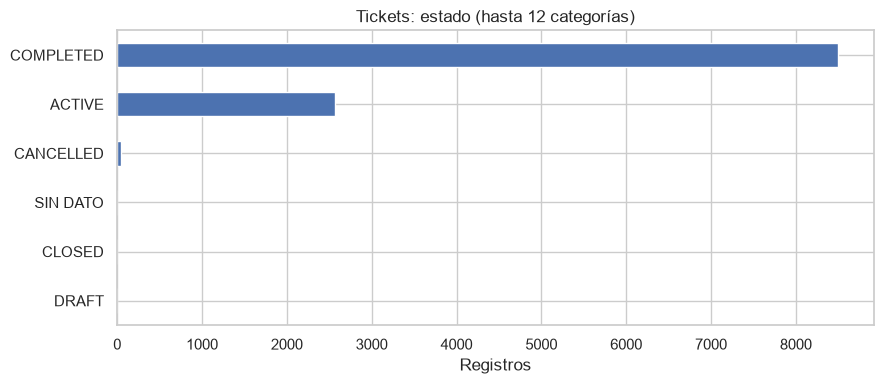

Tickets - tipo_equipo


,Frecuencia,Proporción,%
tipo_equipo,,,
IMM,5336,0.480,48.029
ROBOT,1827,0.164,16.445
SECADOR,905,0.081,8.146
TERMOREGULADOR,673,0.061,6.058
CARGADOR,590,0.053,5.311
BLENDER,562,0.051,5.059
SIN DATO,239,0.022,2.151
CONTROLADOR,168,0.015,1.512
FIXTURE,165,0.015,1.485


Moda observada: ['IMM']
Categorías observadas con menos de 1%: 56
Suma de porcentajes: 100.0


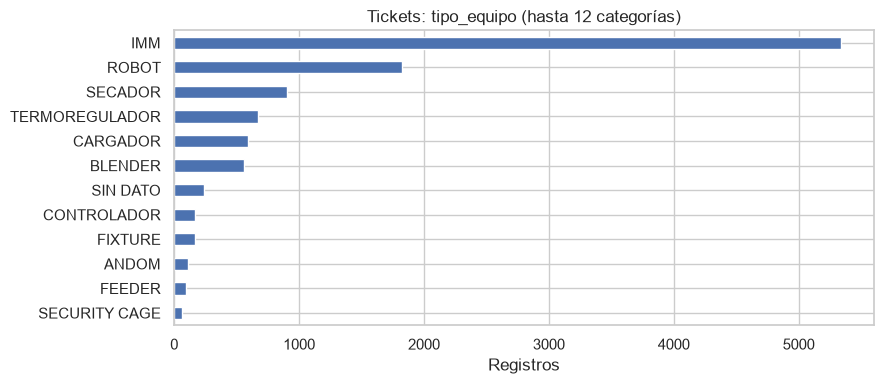

Tickets - condicion


,Frecuencia,Proporción,%
condicion,,,
UP,9823,0.884,88.416
DOWN,1277,0.115,11.494
SIN DATO,10,0.001,0.090


Moda observada: ['UP']
Categorías observadas con menos de 1%: 0
Suma de porcentajes: 100.0


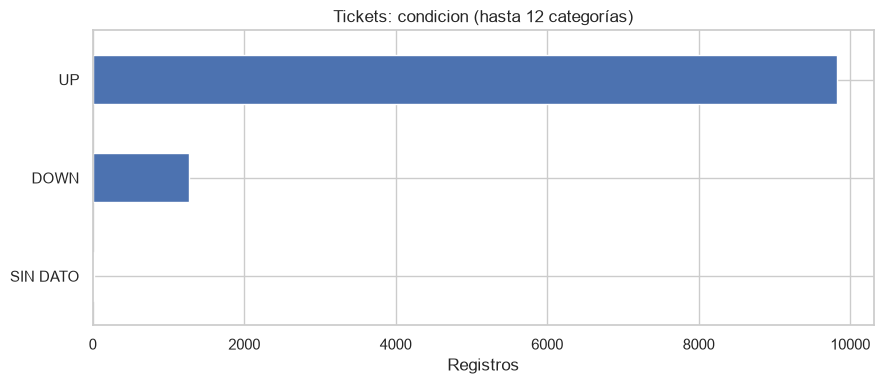

Tickets - area


,Frecuencia,Proporción,%
area,,,
MOLDEO,10816,0.974,97.354
OPERACIONES SECUNDARIAS,145,0.013,1.305
TOOL ROOM,141,0.013,1.269
SIN DATO,5,0.000,0.045
GDL B7,2,0.000,0.018
FLEXTRONICS,1,0.000,0.009


Moda observada: ['MOLDEO']
Categorías observadas con menos de 1%: 2
Suma de porcentajes: 100.0


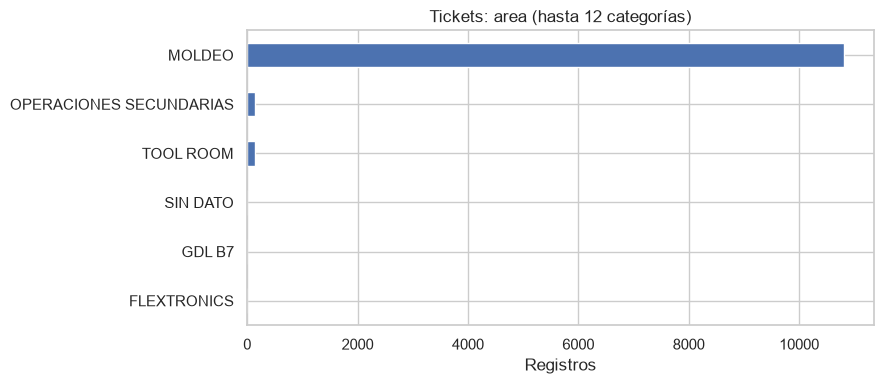

Paros - motivo


,Frecuencia,Proporción,%
motivo,,,
MANTENIMIENTO - MANTTO. CORRECTIVO,7891,0.776,77.614
CAMBIO DE MODELO - FALLA MANTENIMIENTO,2201,0.216,21.648
MANTENIMIENTO - FALTA DE REFACCIONES,44,0.004,0.433
MANTENIMIENTO - LIMPIEZA DE HUSILLO,31,0.003,0.305


Moda observada: ['MANTENIMIENTO - MANTTO. CORRECTIVO']
Categorías observadas con menos de 1%: 2
Suma de porcentajes: 100.0


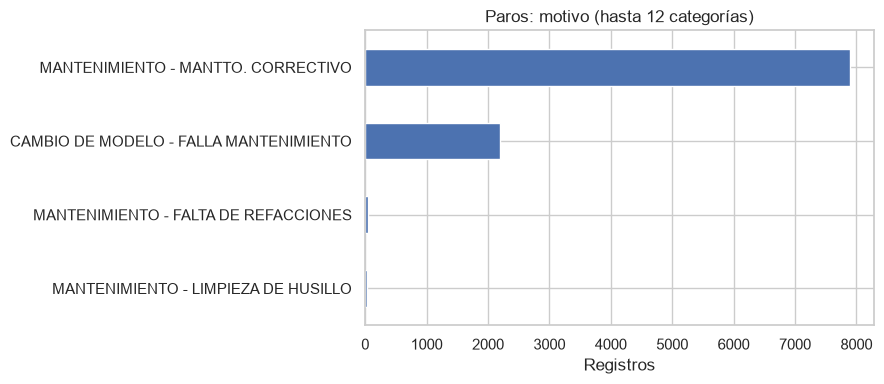

Paros - tipo_equipo


,Frecuencia,Proporción,%
tipo_equipo,,,
IMM,5056,0.497,49.730
ROBOT,2053,0.202,20.193
SIN DATO,963,0.095,9.472
SECADOR,458,0.045,4.505
TERMOREGULADOR,456,0.045,4.485
BLENDER,345,0.034,3.393
CARGADOR,224,0.022,2.203
0,154,0.015,1.515
FIXTURE,143,0.014,1.407


Moda observada: ['IMM']
Categorías observadas con menos de 1%: 18
Suma de porcentajes: 100.0


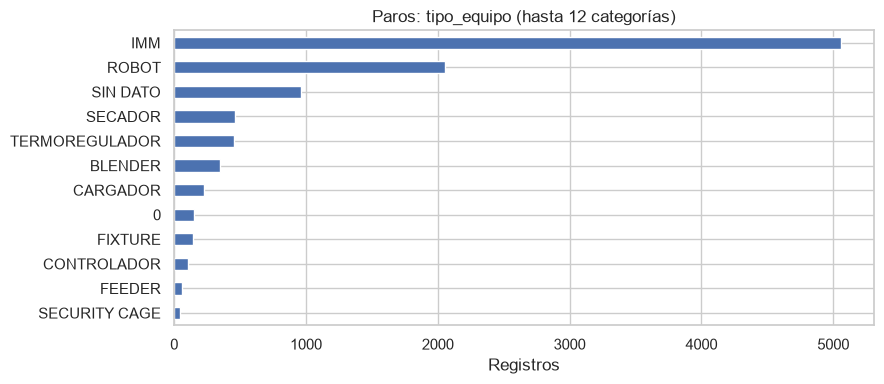

Paros - correctivo


,Frecuencia,Proporción,%
correctivo,,,
CORRECTIVE,7716,0.759,75.893
SIN DATO,1259,0.124,12.383
NOT CORRECTIVE,1192,0.117,11.724


Moda observada: ['CORRECTIVE']
Categorías observadas con menos de 1%: 0
Suma de porcentajes: 100.0


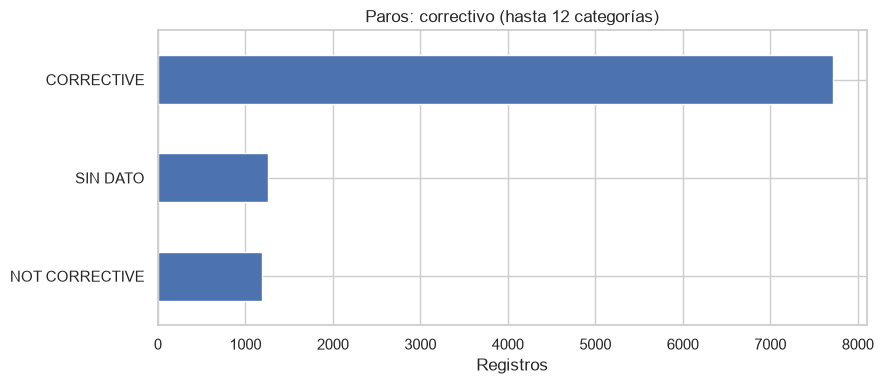

Paros - marca


,Frecuencia,Proporción,%
marca,,,
NISSEI,2308,0.227,22.701
KRAUSS MAFFEI,1675,0.165,16.475
SIN DATO,1491,0.147,14.665
WITTMANN,1356,0.133,13.337
SEPRO,1214,0.119,11.941
CONAIR,618,0.061,6.078
ENGEL,520,0.051,5.115
BATTENFELD,466,0.046,4.583
COMET,162,0.016,1.593


Moda observada: ['NISSEI']
Categorías observadas con menos de 1%: 10
Suma de porcentajes: 100.0


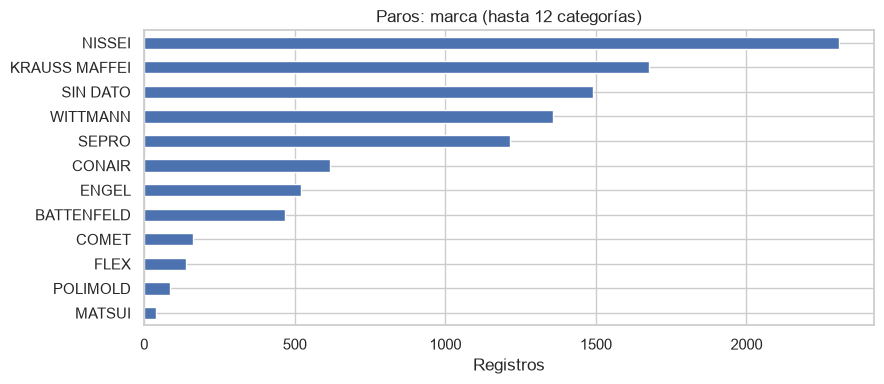

In [8]:
categoricas = [("Tickets", tickets, ["estado", "tipo_equipo", "condicion", "area"]),
               ("Paros", paros, ["motivo", "tipo_equipo", "correctivo", "marca"])]

for nombre, df, columnas in categoricas:
    for col in columnas:
        frecuencia = df[col].fillna("SIN DATO").value_counts().to_frame("Frecuencia")
        frecuencia["Proporción"] = frecuencia["Frecuencia"] / len(df)
        frecuencia["%"] = frecuencia["Proporción"] * 100
        print(nombre, "-", col)
        display(frecuencia)
        print("Moda observada:", df[col].mode().tolist())
        print("Categorías observadas con menos de 1%:", ((frecuencia["%"] < 1) & (frecuencia.index != "SIN DATO")).sum())
        print("Suma de porcentajes:", round(frecuencia["%"].sum(), 2))
        frecuencia["Frecuencia"].head(12).sort_values().plot.barh()
        plt.title(f"{nombre}: {col} (hasta 12 categorías)")
        plt.xlabel("Registros")
        plt.ylabel("")
        plt.tight_layout()
        plt.show()

Las tablas incluyen todas las categorías y los faltantes, por lo que el denominador es el total de filas de cada base preparada. Las gráficas muestran hasta 12 categorías para que las etiquetas sean legibles. No se calculan frecuencias acumuladas porque las categorías no tienen un orden definido.

## 4. Variables numéricas

In [9]:
numericas = {"Reparación (h, unidad supuesta)": tickets["reparacion_h"], "Paro por intervalo (h)": paros["paro_h"]}
resumen = pd.DataFrame({nombre: serie.describe() for nombre, serie in numericas.items()}).T
resumen["varianza"] = [s.var() for s in numericas.values()]
resumen["IQR"] = [s.quantile(.75) - s.quantile(.25) for s in numericas.values()]
resumen["asimetria"] = [s.skew() for s in numericas.values()]
resumen["curtosis_exceso"] = [s.kurt() for s in numericas.values()]
display(resumen)
print("Moda de reparación:", tickets["reparacion_h"].mode().tolist())

,count,mean,std,min,25%,50%,75%,max,varianza,IQR,asimetria,curtosis_exceso
"Reparación (h, unidad supuesta)","11,107.000",1.197,2.004,0.000,0.250,0.500,1.250,37.000,4.016,1.000,5.363,53.005
Paro por intervalo (h),"10,166.000",1.010,2.210,0.000,0.109,0.394,1.052,67.825,4.885,0.943,11.533,251.319


Moda de reparación: [0.0]


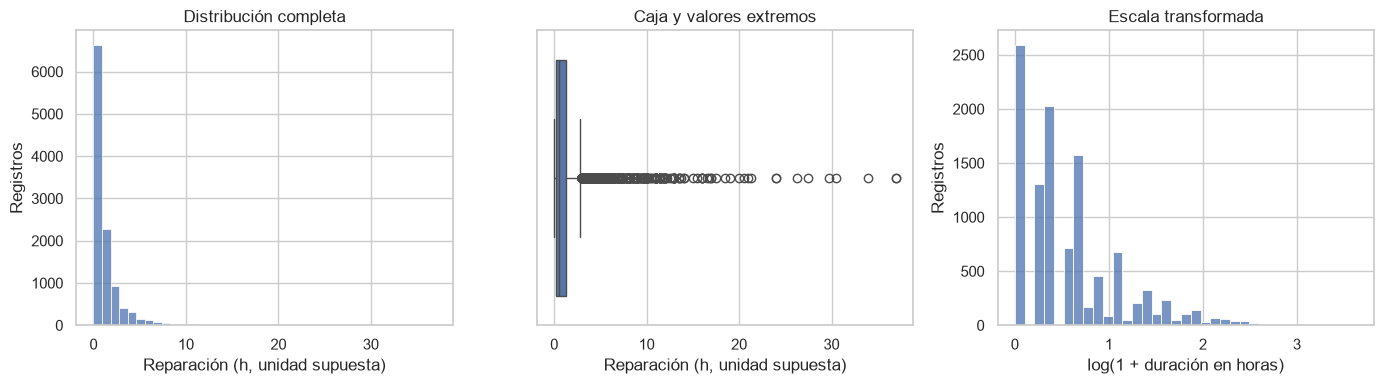

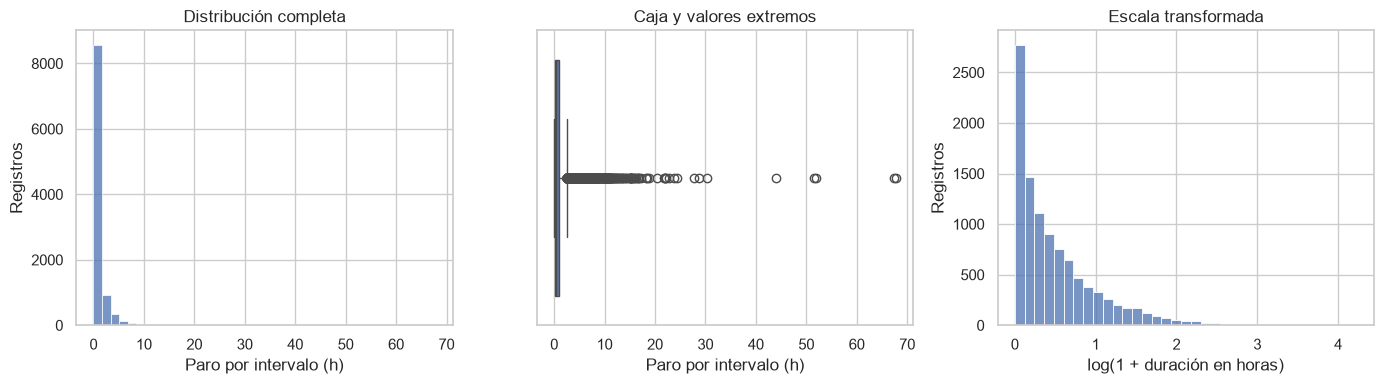

In [10]:
for nombre, serie in numericas.items():
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    sns.histplot(serie, bins=40, ax=axes[0])
    axes[0].set_xlabel(nombre)
    axes[0].set_ylabel("Registros")
    axes[0].set_title("Distribución completa")
    sns.boxplot(x=serie, ax=axes[1])
    axes[1].set_xlabel(nombre)
    axes[1].set_title("Caja y valores extremos")
    sns.histplot(np.log1p(serie.dropna()), bins=35, ax=axes[2])
    axes[2].set_xlabel("log(1 + duración en horas)")
    axes[2].set_ylabel("Registros")
    axes[2].set_title("Escala transformada")
    plt.tight_layout()
    plt.show()

La transformación log(1 + duración) permite ver mejor los tiempos cortos sin borrar los extremos. Los estadísticos se calculan en la escala original. La moda resulta útil para la reparación porque hay valores de captura redondeados; para el paro continuo depende demasiado de la precisión. La forma del histograma también depende de sus intervalos, por lo que no se afirma que existan varias poblaciones solo por sus picos.

Ambas distribuciones tienen una cola larga hacia la derecha. En reparación, la media es 1.20 h y la mediana 0.50 h; en los paros, 1.01 h y 0.39 h. La asimetría y la curtosis positiva son especialmente altas en los paros. Unos pocos intervalos largos elevan el promedio, por lo que la mediana y el IQR describen mejor una duración habitual.

In [11]:
atipicos = []
for nombre, serie in numericas.items():
    q1, q3 = serie.quantile([.25, .75])
    iqr = q3 - q1
    fuera_iqr = (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)
    z = (serie - serie.mean()) / serie.std()
    atipicos.append([nombre, serie.count(), q1 - 1.5 * iqr, q3 + 1.5 * iqr, fuera_iqr.sum(), z.abs().gt(3).sum(), (fuera_iqr & z.abs().gt(3)).sum()])
display(pd.DataFrame(atipicos, columns=["Variable", "n válido", "Límite inferior", "Límite superior", "Fuera de IQR", "|z| > 3", "Ambos"]))
display(paros.nlargest(10, "paro_h")[["ticket", "equipo", "inicio", "paro_h"]])

,Variable,n válido,Límite inferior,Límite superior,Fuera de IQR,|z| > 3,Ambos
0,"Reparación (h, unidad supuesta)",11107,-1.250,2.750,1258,215,215
1,Paro por intervalo (h),10166,-1.305,2.465,1009,150,150


,ticket,equipo,inicio,paro_h
38,REQ-1759753,CHARROS,2026-08-21 15:25:35.380,67.825
107,REQ-1757496,HIDALGO,2026-08-15 15:57:13.980,67.407
6286,REQ-1585766,NAYARIT,2025-08-02 17:44:30.347,51.999
392,REQ-1743764,CONSENTIDA,2026-07-26 07:29:59.647,51.540
6284,<NA>,LAS VEGAS,2025-08-02 21:49:09.417,43.925
10136,REQ-1494472,LAGLORIOSA,2025-01-03 13:13:15.543,30.235
4513,<NA>,YUCATAN,2025-11-18 09:02:05.370,28.693
6163,<NA>,LO JEFE,2025-08-11 09:37:34.090,27.666
5579,REQ-1604989,PREFERIDA,2025-09-20 12:22:18.757,24.382
6177,<NA>,MIKE ROVER,2025-08-10 10:19:46.753,23.699


Los dos criterios señalan observaciones para revisión, no errores confirmados. En distribuciones asimétricas pueden dar conteos muy distintos. Ninguna observación se elimina solo por ser atípica.

## 5. Relaciones entre variables

### Tipo de equipo y condición

La tabla de contingencia usa tickets con ambas categorías disponibles. Se muestran conteos y porcentajes con tres denominadores distintos.

Tickets con ambas categorías: 10861


condicion,DOWN,UP
tipo_equipo,,
AFILADOR,1,1
ANDOM,6,104
BIN,0,1
BLADE,0,2
BLENDER,67,495
CARGADOR,85,505
CARRITO AGV,0,34
CNC GRAPHITE,5,15
CNC STEEL,1,21


Porcentaje del total


condicion,DOWN,UP
tipo_equipo,,
AFILADOR,0.009,0.009
ANDOM,0.055,0.958
BIN,0.000,0.009
BLADE,0.000,0.018
BLENDER,0.617,4.558
CARGADOR,0.783,4.650
CARRITO AGV,0.000,0.313
CNC GRAPHITE,0.046,0.138
CNC STEEL,0.009,0.193


Porcentaje por fila


condicion,DOWN,UP
tipo_equipo,,
AFILADOR,50.000,50.000
ANDOM,5.455,94.545
BIN,0.000,100.000
BLADE,0.000,100.000
BLENDER,11.922,88.078
CARGADOR,14.407,85.593
CARRITO AGV,0.000,100.000
CNC GRAPHITE,25.000,75.000
CNC STEEL,4.545,95.455


Porcentaje por columna


condicion,DOWN,UP
tipo_equipo,,
AFILADOR,0.080,0.010
ANDOM,0.481,1.082
BIN,0.000,0.010
BLADE,0.000,0.021
BLENDER,5.369,5.149
CARGADOR,6.811,5.253
CARRITO AGV,0.000,0.354
CNC GRAPHITE,0.401,0.156
CNC STEEL,0.080,0.218


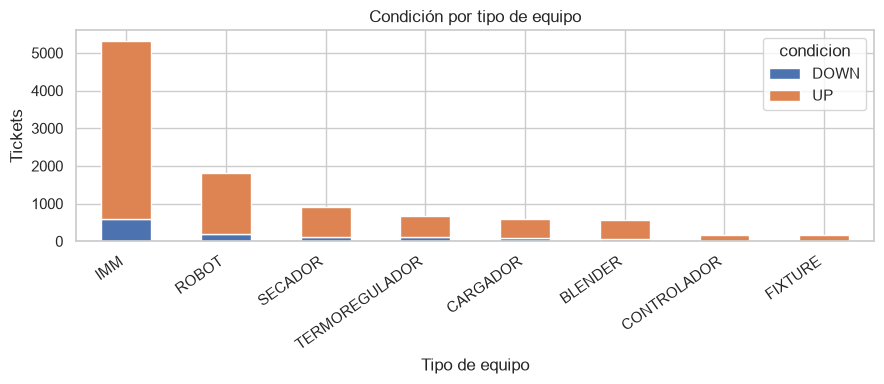

In [12]:
tabla = pd.crosstab(tickets["tipo_equipo"], tickets["condicion"])
print("Tickets con ambas categorías:", tabla.to_numpy().sum())
display(tabla)
print("Porcentaje del total")
display(tabla / tabla.to_numpy().sum() * 100)
print("Porcentaje por fila")
display(tabla.div(tabla.sum(axis=1), axis=0) * 100)
print("Porcentaje por columna")
display(tabla.div(tabla.sum(axis=0), axis=1) * 100)
top = tabla.sum(axis=1).nlargest(8).index
tabla.loc[top].plot.bar(stacked=True)
plt.title("Condición por tipo de equipo")
plt.xlabel("Tipo de equipo")
plt.ylabel("Tickets")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### Tiempo muerto por tipo de equipo

,count,mean,std,min,25%,50%,75%,max,IQR,total_h
tipo_equipo,,,,,,,,,,
IMM,"5,056.000",1.058,2.439,0.000,0.110,0.411,1.068,67.407,0.958,"5,349.690"
ROBOT,"2,053.000",1.008,1.867,0.000,0.144,0.418,1.074,30.235,0.930,"2,068.968"
TERMOREGULADOR,456.000,1.439,1.771,0.001,0.226,0.781,1.946,15.916,1.720,655.963
SECADOR,458.000,1.209,1.856,0.001,0.058,0.338,1.660,11.068,1.602,553.517
BLENDER,345.000,0.797,1.198,0.002,0.179,0.420,0.798,10.861,0.619,274.816
FIXTURE,143.000,1.220,1.454,0.009,0.273,0.650,1.756,7.207,1.483,174.516
CARGADOR,224.000,0.727,1.418,0.002,0.113,0.355,0.915,18.187,0.802,162.799
0,154.000,0.827,1.089,0.002,0.153,0.441,0.960,7.621,0.807,127.310
FOIL FEEDER,11.000,8.189,19.847,0.285,1.490,2.362,2.644,67.825,1.154,90.081


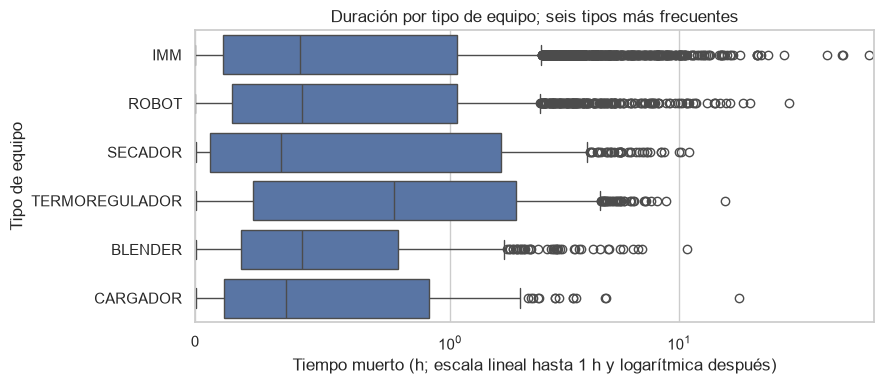

In [13]:
grupos = paros.groupby("tipo_equipo")["paro_h"].describe()
grupo_iqr = grupos["75%"] - grupos["25%"]
grupo_total = paros.groupby("tipo_equipo")["paro_h"].sum(min_count=1)
grupo_resumen = grupos.assign(IQR=grupo_iqr, total_h=grupo_total).sort_values("total_h", ascending=False)
display(grupo_resumen)

top_tipos = paros["tipo_equipo"].value_counts().head(6).index
sns.boxplot(data=paros[paros["tipo_equipo"].isin(top_tipos)], x="paro_h", y="tipo_equipo", order=top_tipos)
plt.xscale("symlog", linthresh=1)
plt.xlim(left=0)
plt.title("Duración por tipo de equipo; seis tipos más frecuentes")
plt.xlabel("Tiempo muerto (h; escala lineal hasta 1 h y logarítmica después)")
plt.ylabel("Tipo de equipo")
plt.tight_layout()
plt.show()

Los tamaños de grupo son diferentes y una suma alta puede deberse a más registros o a paros más largos. La media, la mediana y el IQR permiten separar esas situaciones. No se conoce el número de equipos activos ni sus horas disponibles, así que estos resultados no son tasas de falla ni medidas de disponibilidad.

### Reparación y tiempo muerto por ticket

Se suman primero los intervalos por ticket y después se hace una unión uno a uno. Los tickets sin enlace no se convierten en paros de cero horas. La columna `Downtime` de la hoja `Data` depende de fórmulas con referencias externas; aquí se recalcula la suma desde el archivo de paros.

Tickets analizados:

 11110
IDs válidos en paros: 4931
Tickets enlazados: 4928
Pares con ambos tiempos: 4928
Tickets sin enlace: 6182
IDs de paros sin ticket analizable: 3


,reparacion_h,paro_total_h
reparacion_h,1.000,0.340
paro_total_h,0.340,1.000


,reparacion_h,paro_total_h
reparacion_h,1.000,0.321
paro_total_h,0.321,1.000


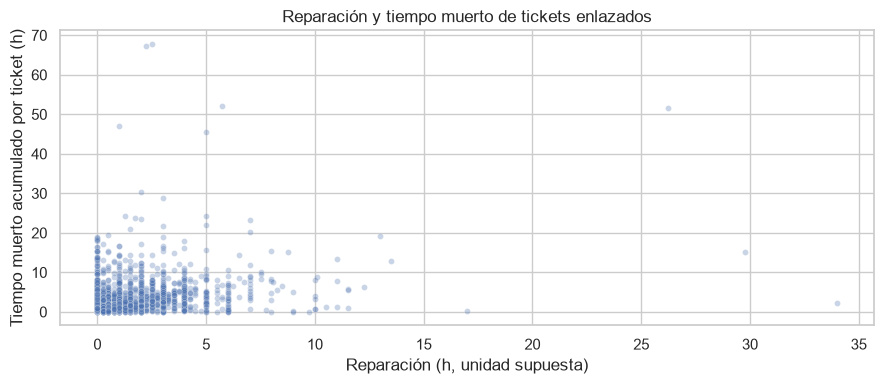

In [14]:
paro_ticket = paros.dropna(subset=["ticket"]).groupby("ticket")["paro_h"].sum(min_count=1).rename("paro_total_h")
comparacion = tickets.merge(paro_ticket, on="ticket", how="inner", validate="one_to_one")
pares = comparacion[["reparacion_h", "paro_total_h"]].dropna()
print("Tickets analizados:", len(tickets))
print("IDs válidos en paros:", paros["ticket"].nunique())
print("Tickets enlazados:", len(comparacion))
print("Pares con ambos tiempos:", len(pares))
print("Tickets sin enlace:", len(tickets) - len(comparacion))
print("IDs de paros sin ticket analizable:", (~paro_ticket.index.isin(tickets["ticket"])).sum())
display(pares.corr(method="pearson"))
display(pares.corr(method="spearman"))
sns.scatterplot(data=pares, x="reparacion_h", y="paro_total_h", alpha=.3, s=18)
plt.title("Reparación y tiempo muerto de tickets enlazados")
plt.xlabel("Reparación (h, unidad supuesta)")
plt.ylabel("Tiempo muerto acumulado por ticket (h)")
plt.tight_layout()
plt.show()

Pearson resume la asociación lineal y Spearman permite comparar el orden de las duraciones. Los extremos pueden afectar mucho a Pearson. No se interpreta la relación como causal, ni se asume que reparación y paro deban durar lo mismo. La comparación solo describe los tickets que pudieron enlazarse.

En los 4,928 pares disponibles, Pearson es 0.340: hay una asociación positiva, aunque los puntos están bastante dispersos. El tiempo de reparación por sí solo no describe bien la variación del tiempo muerto.

## 6. Comportamiento mensual

,tickets,reparacion_mediana_h,intervalos,duraciones_validas,paro_total_h,paro_mediana_h
fecha,,,,,,
2025-01-01,859,0.500,616,616,878.471,0.633
2025-02-01,635,0.500,581,581,651.004,0.500
2025-03-01,586,0.500,510,510,633.831,0.586
2025-04-01,594,0.500,484,484,537.902,0.540
2025-05-01,613,0.500,477,477,576.066,0.560
2025-06-01,586,0.251,580,580,673.611,0.616
2025-07-01,622,0.500,601,601,644.647,0.402
2025-08-01,532,0.250,401,401,565.223,0.503
2025-09-01,652,0.500,597,597,490.385,0.294


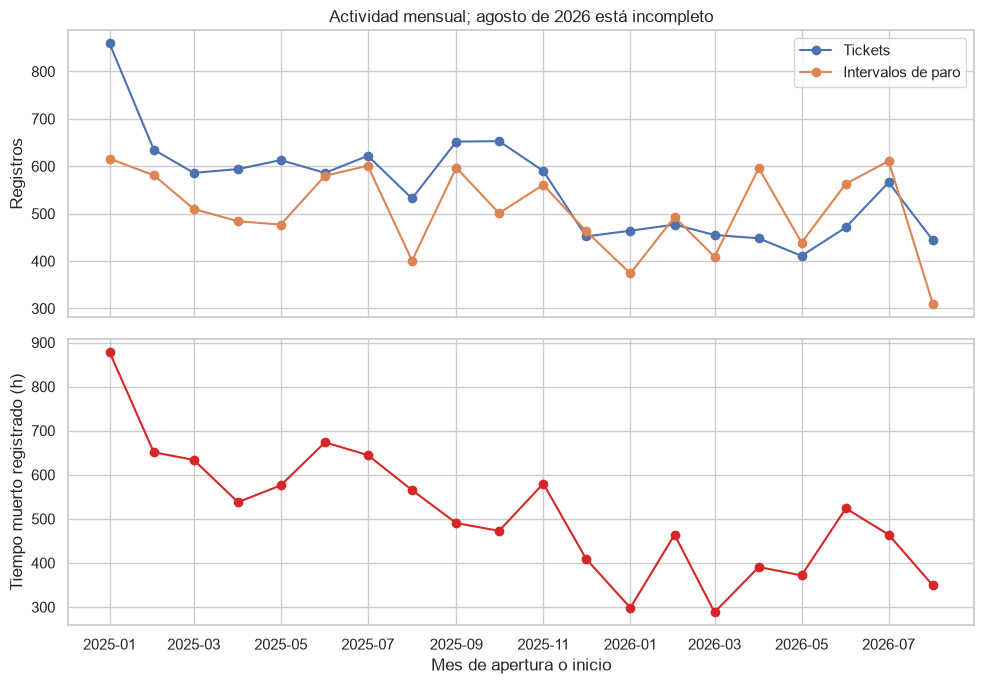

In [15]:
mensual_tickets = tickets.set_index("fecha").resample("MS").agg(tickets=("ticket", "size"), reparacion_mediana_h=("reparacion_h", "median"))
mensual_paros = paros.set_index("inicio").resample("MS").agg(intervalos=("paro_h", "size"), duraciones_validas=("paro_h", "count"), paro_total_h=("paro_h", "sum"), paro_mediana_h=("paro_h", "median"))
mensual = mensual_tickets.join(mensual_paros, how="outer")
display(mensual)
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(mensual.index, mensual["tickets"], marker="o", label="Tickets")
axes[0].plot(mensual.index, mensual["intervalos"], marker="o", label="Intervalos de paro")
axes[0].set_ylabel("Registros")
axes[0].legend()
axes[1].plot(mensual.index, mensual["paro_total_h"], marker="o", color="tab:red")
axes[1].set_ylabel("Tiempo muerto registrado (h)")
axes[1].set_xlabel("Mes de apertura o inicio")
axes[0].set_title("Actividad mensual; agosto de 2026 está incompleto")
plt.tight_layout()
plt.show()

Los meses se calculan desde las fechas, no desde el orden de las etiquetas de Excel. Agosto de 2026 está incompleto y el inicio de enero de 2025 tampoco garantiza cobertura total. Un descenso en el último mes no demuestra una mejora. Los registros de un mismo equipo pueden depender entre sí y menos de dos años completos no bastan para establecer una estacionalidad estable.

## 7. Resultados

In [16]:
print(f"La base preparada contiene {len(tickets):,} tickets únicos y {len(paros):,} intervalos de paro.")
for nombre, serie in numericas.items():
    print(f"{nombre}: media {serie.mean():.2f}, mediana {serie.median():.2f}, desviación {serie.std():.2f}, IQR {serie.quantile(.75) - serie.quantile(.25):.2f}.")
print(f"Tiempo muerto registrado: {total_paros:,.2f} h; falta una duración numérica.")
print(f"El tipo con más horas clasificadas es {grupo_resumen.index[0]}: {grupo_resumen.iloc[0]['total_h']:,.2f} h.")
print(f"Paros sin tipo de equipo: {paros['tipo_equipo'].isna().sum():,} ({paros['tipo_equipo'].isna().mean():.1%}).")
print(f"Correlación de Pearson entre reparación y paro: {pares.corr().iloc[0, 1]:.3f}, con {len(pares):,} pares.")
completos = mensual.iloc[1:-1]
print(f"Mayor suma mensual entre meses interiores: {completos['paro_total_h'].idxmax():%Y-%m}, con {completos['paro_total_h'].max():,.2f} h.")

La base preparada contiene 11,110 tickets únicos y 10,167 intervalos de paro.
Reparación (h, unidad supuesta): media 1.20, mediana 0.50, desviación 2.00, IQR 1.00.
Paro por intervalo (h): media 1.01, mediana 0.39, desviación 2.21, IQR 0.94.
Tiempo muerto registrado: 10,264.23 h; falta una duración numérica.
El tipo con más horas clasificadas es IMM: 5,349.69 h.
Paros sin tipo de equipo: 963 (9.5%).
Correlación de Pearson entre reparación y paro: 0.340, con 4,928 pares.
Mayor suma mensual entre meses interiores: 2025-06, con 673.61 h.


Los paros suman 10,264.23 h registradas. IMM concentra 5,349.69 h, aproximadamente 52.1% del total, y también es el tipo más frecuente. Esto no demuestra que sea menos confiable: falta conocer cuántos equipos de cada tipo operan y durante cuánto tiempo. Un 9.5% de los intervalos no tiene tipo de equipo identificado.

Los tiempos largos merecen revisión, especialmente el paro máximo de 67.82 h. Contar una sola vez los seis intervalos repetidos reduce el total en 2.64 h, un efecto pequeño sobre la suma, aunque sigue siendo un problema de calidad. La serie mensual fluctúa y muestra niveles generalmente menores en 2026 que al inicio de 2025; no puede atribuirse esa diferencia a mejoras sin confirmar cobertura y actividad de la planta.

Antes de usar estos datos para evaluar desempeño, conviene confirmar la unidad de reparación, revisar las dos duraciones señaladas y resolver los enlaces duplicados. Las diferencias entre grupos son descriptivas; no se probó significancia estadística.

## 8. Propuesta de análisis

El siguiente paso será estudiar qué características se relacionan con los paros más largos y estimar su duración al momento de reportarlos. Esto podría ayudar a priorizar la atención de mantenimiento. Primero habrá que confirmar con el socio formador las unidades, la cobertura de los archivos y qué información se conoce al inicio de cada evento. Los modelos que se describen aquí son una propuesta; todavía no se han entrenado.

### Variables dependientes e independientes

| Análisis | Variable dependiente | Variables independientes propuestas |
| --- | --- | --- |
| Duración de un paro | `Downtime` de la hoja `2024`, en horas por intervalo | Tipo de equipo (`Equipo 26`), marca (`Brand`), motivo (`Reason`) y mes, día de la semana y hora obtenidos de `Opened`. |
| Duración de una reparación | `Repair Time` de la hoja `Data`, por ticket único y con su unidad confirmada | Tipo de equipo (`EQ Type`), área (`Functional area`) y variables de calendario obtenidas de `Opened`. |
| Identificación de paros prolongados | Indicador de si `Downtime` supera un umbral acordado con el socio formador | Las mismas variables disponibles al inicio que se usen para estimar la duración del paro. |

Cada análisis conservará su unidad de observación: un intervalo para los paros y un ticket para las reparaciones. Para reparación se usarán solicitudes terminadas con una duración válida, después de confirmar el significado de sus estados. Un ticket activo con tiempo cero no se tomará automáticamente como una reparación terminada de duración cero.

Las variables independientes serán candidatas, no causas demostradas. Solo se incluirán si estaban disponibles cuando se habría realizado la predicción. Las clasificaciones de falla podrían agregarse si el socio confirma que se capturan al inicio y no al cerrar el ticket.

No se usarán como predictores la fecha de fin, la descripción del trabajo realizado ni el tiempo final de reparación para anticipar un paro. Estos campos pueden revelar el resultado que se quiere estimar. Los IDs servirán para enlazar y agrupar registros, pero no se tratarán como cantidades.

### Métodos y evaluación

1. **Preparación y análisis descriptivo.** Se partirá de las distribuciones, tablas y comparaciones del EDA. Se revisarán los tickets contradictorios, los intervalos repetidos, los faltantes y las duraciones inconsistentes. Los valores extremos se conservarán salvo que se confirme un error. Las categorías se codificarán con variables indicadoras y los faltantes categóricos tendrán una etiqueta propia. Las filas sin una duración confiable no se usarán para entrenar modelos de esa duración.

2. **Regresión.** Se comenzará con una regresión lineal sobre `log(1 + duración)`, por la asimetría observada. Se construirá un modelo para el paro y otro para la reparación. Como comparación se utilizará un árbol de regresión de poca profundidad, que permite explorar relaciones no lineales e interacciones entre categorías. Se compararán sus errores con una predicción sencilla basada en la mediana del conjunto de entrenamiento. El error absoluto medio (MAE) y la raíz del error cuadrático medio (RMSE) se reportarán en horas, después de devolver las predicciones a su escala original.

3. **Clasificación.** Si el socio necesita distinguir paros prolongados para tomar una decisión, se probará una regresión logística con el indicador definido en la tabla. El umbral de duración se acordará por su relevancia operativa. Se revisarán la matriz de confusión, la precisión y la sensibilidad para los paros prolongados. La elección dependerá del costo de generar una alerta innecesaria frente al de no detectar un paro largo; no se evaluará únicamente el porcentaje de aciertos.

4. **Validación temporal.** Se entrenará con los meses más antiguos y se reservará el tramo más reciente con cobertura suficiente para evaluar. Los registros de un mismo ticket no se repartirán entre entrenamiento y prueba; los tickets que crucen el corte se dejarán fuera de esa comparación. La preparación de categorías y cualquier ajuste se aprenderán solo con los datos de entrenamiento. Se revisarán los errores por tipo de equipo para detectar grupos con pocas observaciones o resultados deficientes.

La propuesta combina regresión y, si responde a una necesidad operativa, clasificación. El clustering no será una primera prioridad porque todavía falta un catálogo consistente de equipos y sus horas de operación. Con esa información podría explorarse después una agrupación de equipos por frecuencia de fallas y duración de paros, sin confundir mayor uso con peor desempeño. Un clustering no tendría variable dependiente.

Los modelos permitirían describir asociaciones y evaluar capacidad predictiva. No demostrarían que un tipo de equipo, una marca o un motivo provoquen una mayor duración.

## 9. Preguntas para el socio formador

### Significado y captura de los datos

1. ¿Qué decisión les gustaría apoyar con el análisis: priorizar tickets, asignar personal, reducir tiempo muerto o identificar equipos que requieren atención? ¿En qué momento se tomaría esa decisión?
2. ¿En qué unidad se registra `Repair Time`? ¿Representa tiempo transcurrido, horas de trabajo de una persona o la suma de horas de varios técnicos? ¿Qué significan sus valores en cero?
3. ¿`Opened` y `Update` de la hoja `2024` corresponden al inicio y al fin reales del paro? ¿Cómo se explica la diferencia entre esas fechas y `Downtime` en el registro señalado en el EDA?
4. ¿Los estados `UP` y `DOWN` describen la condición del equipo al abrir el ticket o su estado más reciente? ¿Qué campos se conocen al inicio y cuáles se completan al cierre?

### Calidad, relaciones y cobertura

5. ¿Por qué hay tickets con varias versiones y valores diferentes? ¿Existe una fecha o un criterio para identificar la versión correcta?
6. ¿Los seis intervalos con el mismo equipo, inicio y fin son duplicados de captura o registros distintos? Cuando un intervalo tiene dos tickets asociados, ¿cómo debe asignarse su duración?
7. ¿Qué significan los registros sin ticket y los tickets sin paro enlazado? ¿La ausencia de un enlace indica que no hubo paro o que faltó registrar la relación?
8. ¿Existe un diccionario actualizado de columnas y un catálogo único de equipos? Algunos encabezados no coinciden con su contenido y hay categorías como `0` cuyo significado no está documentado.
9. ¿Los archivos incluyen todos los eventos de enero de 2025 a agosto de 2026? ¿Hubo cambios de sistema, criterios de captura, equipos incluidos o periodos sin registro? ¿Cuál es el último mes que consideran completo?

### Contexto operativo

10. ¿Cuántos equipos de cada tipo estaban activos y cuántas horas operaron por mes? ¿Se cuenta con turnos, volumen de producción y mantenimiento programado para comparar equipos con distinta carga de trabajo?
11. ¿A partir de cuántas horas consideran que un paro es prolongado o crítico? ¿Ese límite depende del equipo, la línea o el producto? ¿Qué cuesta más: una alerta innecesaria o no anticipar un paro largo?
12. ¿Los paros muy largos incluyen espera de refacciones, falta de personal, periodos fuera de turno o tiempo sin producción programada? ¿Es posible separar esos tiempos del trabajo efectivo de reparación?